# TPU Basics

Learning how to program in JAX, which is the PyTorch equivalent for TPUs. From reading, it's more decribed as NumPy + Autograd & Flax (a different package we'll introduce later) is like the helper functions that come with PyTorch torch.nn or Keras in Tensorflow.

In this notebook, I'm going to explore the basic of the package, and finish with programming a linear regression model using Stochastic Gradient Descent (SGD), like what I do with the MSc Data Science students.

*Note: Building a CPD training programme based on learning Deep Learning with Google TPUs would be an excellent idea, especially as GPU costs are sky-rocketing, ASCIS are performant and cheap - and people understand less how to program with them, leaving an open market for a company to capitalize on*

In [35]:
import jax
import time
import jax.numpy as jnp

## Immutable Arrays:

jax.numpy (conventionally imported as jnp) matches the standard NumPy API almost 1:1, but **arrays are immutable**. You cannot mutate array elements in place.

In [36]:
x = jnp.array([1.0, 2.0, 3.0])

# x[0] = 5.0 <--- This raises a TypeError!

# Out-of-place update (creates a new array reference):
x_updated = x.at[0].set(5.0) # [5.0, 2.0, 3.0]

print(f"The Values of X are: {x}")
print(f"The values of x_updated are: {x_updated}")


The Values of X are: [1. 2. 3.]
The values of x_updated are: [5. 2. 3.]


## Explicit Randomness
Unlike NumPy or PyTorch, JAX has no globabl random seed state. Global mutable state breaks reproducibility across parallel threads and compilation passes. Instead, you create and split explicit **PNRG keys**:

In [37]:
# Initalize a Key:
key = jax.random.key(42)
print(key)

# To generate random numbers, split the key:
key, subkey = jax.random.split(key)
print(key, subkey)

noise = jax.random.normal(subkey, shape=(5,))
print(noise)

Array((), dtype=key<fry>) overlaying:
[ 0 42]
Array((), dtype=key<fry>) overlaying:
[1832780943  270669613] Array((), dtype=key<fry>) overlaying:
[  64467757 2916123636]
[ 0.60576403  0.7990441  -0.908927   -0.63525754 -1.2226585 ]


## Automatic Differentiation

JAX treats differentiation as a functional operator. Given a Python function $f(x)$.
jax.grad(f) returns a new function representing $\delta f(x)$

- jax.grad(f): Differentiaties with respect the first positional argument by default.
- jax.value_and_grad(f): returns both the function output (e.g. loss) and its gradient in a single forward/ backwards pass.

In [38]:
def f(x):
    return x**2 + 3.0*x

df = jax.grad(f)
print(f"The absolute differential of f w.r.t x is {df(2.0)}") # 2 x 2.0 + 3.0 = 7.0


# IG Example of Partitial Differential:
def g(x, y):
    return 3*x*y + 3*y

dg_y = jax.grad(g, argnums=1) # With respect to y
print(f"The partial differential of g w.r.t y is {dg_y(1.0, 3.0)}")

The absolute differential of f w.r.t x is 7.0
The partial differential of g w.r.t y is 6.0


## Just-In-Time Compilation

jax.jit traces Python functions into an intermediate representation and compiles them down to optimized XLA machine code (fusing operations like add/multiply) into single hardware kernels.

Functions compiled with @jax.jit must be pure:
- No side-effects (e.g. appending to external Python list of modifying global variables)
- Flow control depending on dynamic values (like if x[0] > 0:) requires JAX control flow primitives (lax.cond, lax.while_loop), though standard loops count over static variables work out of the box.

## Linear Regression with Custom SGD (Basic Implementation)
Let's train a Linear Regression model, designing our own Stochastic Gradient Descent (SGD) pipeline:

*Note: The mean is literally used just to get the array in the right shape of (1,)*



In [66]:
# 1. Generate a single data sample
key = jax.random.key(1337)

X = jnp.array([3.0])
y = jnp.array([9.0])

m = jax.random.normal(key)

print(f"Data Point (X, y) {(X,y)} | Initial Value m: {m}")

# 2. Forward Pass:
def predict(m, X):
    return m*X

# 3. Loss Function:
def mse_loss(m, X, y):
    pred = predict(m,X)
    return jnp.array((pred - y)**2).reshape()

# Optimizer
def train_step(m, X, y, lr=0.05):
    loss, grads = jax.value_and_grad(mse_loss)(m, X, y)
    new_param = m - lr*grads
    return new_param, loss

epochs = 10
# Training Loop:
for epoch in range(epochs):
    m, loss = train_step(m, X, y)
    print(f"Loss: {loss}, New Parameter: {m}")


Data Point (X, y) (Array([3.], dtype=float32), Array([9.], dtype=float32)) | Initial Value m: -0.023382708430290222
Loss: 82.26759338378906, New Parameter: 2.697661876678467
Loss: 0.8226759433746338, New Parameter: 2.96976637840271
Loss: 0.008226689882576466, New Parameter: 2.996976613998413
Loss: 8.227209036704153e-05, New Parameter: 2.999697685241699
Loss: 8.225479177781381e-07, New Parameter: 2.999969720840454
Loss: 8.208189683500677e-09, New Parameter: 2.9999969005584717
Loss: 9.094947017729282e-11, New Parameter: 2.999999761581421
Loss: 9.094947017729282e-13, New Parameter: 3.0
Loss: 0.0, New Parameter: 3.0
Loss: 0.0, New Parameter: 3.0


## Linear Regression with Custom SGD (Intermediate Implementation)
Let's train a Linear Regression model, designing our own Stochastic Gradient Descent (SGD) pipeline:

In [79]:
# 1. Generating Synthetic Data:

key = jax.random.key(1337)
key_x, key_noise, key_params, key_shuffle = jax.random.split(key, 4)

N = 1000
TRUE_M = 3.5
TRUE_C = 1.2

# Features: shape (N,)
X = jax.random.normal(key_x, shape=(N,))
noise = jax.random.normal(key_noise, shape=(N,)) * 0.2
y = TRUE_M * X + TRUE_C + noise

print(f"Synthetic Features: {X[0:5]}")
print(f"Synthetic Targets: {y[0:5]}")

Synthetic Features: [-1.8442757   0.38579687  0.08905527 -1.9929202   0.08927006]
Synthetic Targets: [-5.300079   2.5121744  1.6625358 -5.923634   1.4676061]


In [80]:
# 2. Model & Loss Function:

# Parameters are stored in a standard Python dictionary (a JAX PyTree)
params = {
    'm': jax.random.normal(key_params),
    'c': jnp.array(0.0)
}

# Forward Pass:
def predict(params, x):
    """Forwards pass: y = m*x + c

    Args:
        params (_type_): Contains the current values of m & c.
        x (_type_): Contains the training data.
    """
    return params['m'] * x + params['c']

# Loss Function:
def mse_loss(params, x_batch, y_batch):
    """Average Mean Squared Error across the batch.

    Args:
        params (_type_): Contains the current values of m & c.
        x_batch (_type_): Contains the batch of training features.
        y_batch (_type_): Contains the bach of training targets.
    """

    preds = predict(params, x_batch)
    return jnp.mean((preds - y_batch)**2)

# Optimization Step:
@jax.jit # 21.7x slower with it commented out, on CPU!
def train_step(params, x_batch, y_batch, lr=0.05):
    """Optimization Step: Compute gradients and update parameters via SGD.
                          Compiled via XLA for fast execution.

    Args:
        params (_type_): Contains the current values of m & c.
        x_batch (_type_): Contains the batch of training features.
        y_batch (_type_): Contaains the batch of trainig targets.
        lr (float, optional): The % of gradient used to update the params. Defaults to 0.05.
    """

    # Compute both loss value and gradients w.r.t 'params'
    loss, grads = jax.value_and_grad(mse_loss)(params, x_batch, y_batch)
    new_params = jax.tree.map(lambda p, g: p - lr * g, params, grads)
    return new_params, loss

In [81]:
# 3. Training Loop
batch_size = 32
epochs = 1000
num_batches = N // batch_size

print(f"Inital: m = {params['m']:.4f}, c = {params['c']:.4f}")

# Start timer
start_time = time.perf_counter()

for epoch in range(epochs):
    # Shuffle indicies at the start of each epoch
    key_shuffle, subkey = jax.random.split(key_shuffle)
    permutation = jax.random.permutation(subkey,N)
    X_shuffled = X[permutation]
    y_shuffled = y[permutation]

    epoch_loss =0.0
    for b in range(num_batches):
        start = b * batch_size
        end = start + batch_size

        x_batch = X_shuffled[start:end]
        y_batch = y_shuffled[start:end]

        params, batch_loss = train_step(params, x_batch, y_batch, lr=0.01)
        epoch_loss += batch_loss

    if (epoch + 1) % 5 == 0:
        avg_loss = epoch_loss / num_batches
        print(f"Epoch {epoch+1:02d} | Loss: {avg_loss:.5f} | m: {params['m']:.4f} | c: {params['c']:.4f}")

# tracks time until the accelerator has finished writing all final parameter arrays
params['m'].block_until_ready()

# Stop time:
end_time = time.perf_counter()
elapsed = end_time - start_time

print("\n--- Final Results ---")
print(f"Total Elapsed time training: {elapsed:.4f}")
print(f"Learned m: {params['m']:.4f} (Ground Truth: {TRUE_M})")
print(f"Learned c: {params['c']:.4f} (Ground Truth: {TRUE_C})")

Inital: m = 0.2271, c = 0.0000
Epoch 05 | Loss: 0.08154 | m: 3.3742 | c: 1.1359
Epoch 10 | Loss: 0.03906 | m: 3.4985 | c: 1.1904
Epoch 15 | Loss: 0.03884 | m: 3.5020 | c: 1.1941
Epoch 20 | Loss: 0.03924 | m: 3.5020 | c: 1.1915
Epoch 25 | Loss: 0.03894 | m: 3.5030 | c: 1.1927
Epoch 30 | Loss: 0.03909 | m: 3.5024 | c: 1.1928
Epoch 35 | Loss: 0.03917 | m: 3.5029 | c: 1.1936
Epoch 40 | Loss: 0.03899 | m: 3.5032 | c: 1.1948
Epoch 45 | Loss: 0.03886 | m: 3.5020 | c: 1.1930
Epoch 50 | Loss: 0.03922 | m: 3.5024 | c: 1.1933
Epoch 55 | Loss: 0.03899 | m: 3.5031 | c: 1.1933
Epoch 60 | Loss: 0.03887 | m: 3.5016 | c: 1.1936
Epoch 65 | Loss: 0.03870 | m: 3.5027 | c: 1.1932
Epoch 70 | Loss: 0.03919 | m: 3.5013 | c: 1.1931
Epoch 75 | Loss: 0.03894 | m: 3.5030 | c: 1.1936
Epoch 80 | Loss: 0.03891 | m: 3.5032 | c: 1.1925
Epoch 85 | Loss: 0.03914 | m: 3.5034 | c: 1.1925
Epoch 90 | Loss: 0.03875 | m: 3.5032 | c: 1.1928
Epoch 95 | Loss: 0.03900 | m: 3.5019 | c: 1.1910
Epoch 100 | Loss: 0.03901 | m: 3.5020 

## Key Mechanics:

1. Parameter Tree Handling - jax.tree.map applied the update function uniformly across arbitraty nested structures. This essentially allows us to avoid the following code:
```
params['m'] = params['m'] - lr * grads['m']
params['c'] = params['c'] - lr * grads['c']
```
2. Gradient composition - jax.value_and_grad(mse_loss) produces gradients that match the exact data structure of params (returning a dictinoary with identical 'm' and 'c' keys).

3. Execution Separation - The entire forward pass, gradient calculation, and paramter update in train_step are fused into a single machine-level kernal via @jax.jit. Python only orchestrated batch slicing and passes memory buffers.

## Questions:

1. Why is @jax.jit only applied to the train_step function?

JAX complies code by **tracing**: When train_step runs for the first time, JAX passes abstract tracer values through the function to record the underlying mathematical graph (the jaxpr).

Because train_step calls mse_loss, which in turn calls predict:
- Both predict and mse_loss are traced automatically.
- Their mathematical operations are directly inlined into the single computational graph of train_step.

Adding @jax.jit to predict or mse_loss would be redundant.

2. Our training loop is not written in a function, why don't we write the entire training loop (with the batching and everything else) into a function and run @jax.jit on that?

When you have standard Python for loop inside a @jax.jit function, JAX does not compile a loop construct; it completely unrolls every interation into a massive, static computation graph.
- If you train 20 epochs with 31 batches per epoch, JAX duplicated the forward pass, backward pass and parameter update in the trace **620 separate times**
- JAX's XLA compilation time scales deeply (often quadratically) with the size of an unrolled graph.
- On a real dataset, in short, this would just blow everything up.

Additionally, Telemetry and Logging (like our print statements of epochs) are consider side-effects, so we would not see any of these things. 

**What we can do** is build an implementation, where instead of just jitting a single train-step, we can jit an entire epoch. This way we can still do reporting, logging, and weight saving between epochs.

##

## Linear Regression with Custom SGD (Advanced)

In this implementation, we'll update so that we are jitting an entire epoch and see what speed-up we get to our Intermediate Solution.

In [84]:
# 1. Generating Synthetic Data:

ey = jax.random.key(1337)
key_x, key_noise, key_params, key_train = jax.random.split(key, 4)

N = 1024
batch_size = 32
num_batches = N // batch_size

TRUE_M = 3.5
TRUE_C = 1.2

# Features: shape (N,)
X = jax.random.normal(key_x, shape=(N,))
noise = jax.random.normal(key_noise, shape=(N,)) * 0.2
y = TRUE_M * X + TRUE_C + noise

print(f"Synthetic Features: {X[0:5]}")
print(f"Synthetic Targets: {y[0:5]}")

# 2. Model & Loss Function:

# Parameters are stored in a standard Python dictionary (a JAX PyTree)
params = {
    'm': jax.random.normal(key_params),
    'c': jnp.array(0.0)
}

# Forward Pass:
def predict(params, x):
    """Forwards pass: y = m*x + c

    Args:
        params (_type_): Contains the current values of m & c.
        x (_type_): Contains the training data.
    """
    return params['m'] * x + params['c']

# Loss Function:
def mse_loss(params, x_batch, y_batch):
    """Average Mean Squared Error across the batch.

    Args:
        params (_type_): Contains the current values of m & c.
        x_batch (_type_): Contains the batch of training features.
        y_batch (_type_): Contains the bach of training targets.
    """

    preds = predict(params, x_batch)
    return jnp.mean((preds - y_batch)**2)

Synthetic Features: [-1.8442757   0.38579687  0.08905527 -1.9929202   0.08927006]
Synthetic Targets: [-5.300079   2.5121744  1.6625358 -5.923634   1.4676061]


In [ ]:
# Optimization + SGD over Epoch (Epoch Step)
# 10 to 11 seconds down to 2.8!
@jax.jit
def train_epoch(params, x_batches, y_batches, lr=0.05):

    def step_fn(carry_params, batch):
        x_b, y_b = batch
        loss, grads = jax.value_and_grad(mse_loss)(carry_params, x_b, y_b)

        # SGD parameter update:
        updated_params = jax.tree.map(lambda p, g: p - lr * g, carry_params, grads)
        
        # Returns: (carry_forward_to_next_step, accumulated_metric)
        return updated_params, loss
    
    final_params, batch_losses = jax.lax.scan(
        step_fn,
        init=params,
        xs=(x_batches, y_batches)
    )

    return final_params, jnp.mean(batch_losses)


epochs = 1000
print(f"Initial: m = {params['m']:.4f}, c = {params['c']:.4f}\n")



start_time = time.perf_counter()
for epoch in range(epochs):
    # Reshuffle data into mini-batch blocks: shape (num_batches, batch_size)
    key_train, subkey = jax.random.split(key_train)
    perm = jax.random.permutation(subkey, N)
    
    X_batched = X[perm].reshape((num_batches, batch_size))
    y_batched = y[perm].reshape((num_batches, batch_size))

    # Single dispatch to accelerator for the entire epoch
    params, epoch_loss = train_epoch(params, X_batched, y_batched, lr=0.01)

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1:02d} | Avg Loss: {epoch_loss:.5f} | m: {params['m']:.4f} | c: {params['c']:.4f}")

params['m'].block_until_ready()

end_time = time.perf_counter()
elapsed = end_time - start_time

# ==========================================
# 5. Final Evaluation
# ==========================================
print("\n--- Final Results ---")
print(f"Time: {elapsed:.4f}")
print(f"Learned m: {params['m']:.4f} (Ground Truth: {TRUE_M})")
print(f"Learned c: {params['c']:.4f} (Ground Truth: {TRUE_C})")

Initial: m = 0.2271, c = 0.0000

Epoch 05 | Avg Loss: 0.07223 | m: 3.3910 | c: 1.1415
Epoch 10 | Avg Loss: 0.03897 | m: 3.4985 | c: 1.1915
Epoch 15 | Avg Loss: 0.03893 | m: 3.5014 | c: 1.1937
Epoch 20 | Avg Loss: 0.03894 | m: 3.5021 | c: 1.1920
Epoch 25 | Avg Loss: 0.03894 | m: 3.5027 | c: 1.1931
Epoch 30 | Avg Loss: 0.03894 | m: 3.5023 | c: 1.1931
Epoch 35 | Avg Loss: 0.03893 | m: 3.5027 | c: 1.1937
Epoch 40 | Avg Loss: 0.03892 | m: 3.5034 | c: 1.1946
Epoch 45 | Avg Loss: 0.03893 | m: 3.5018 | c: 1.1930
Epoch 50 | Avg Loss: 0.03892 | m: 3.5022 | c: 1.1932
Epoch 55 | Avg Loss: 0.03894 | m: 3.5023 | c: 1.1941
Epoch 60 | Avg Loss: 0.03893 | m: 3.5019 | c: 1.1933
Epoch 65 | Avg Loss: 0.03892 | m: 3.5023 | c: 1.1929
Epoch 70 | Avg Loss: 0.03893 | m: 3.5015 | c: 1.1936
Epoch 75 | Avg Loss: 0.03893 | m: 3.5022 | c: 1.1933
Epoch 80 | Avg Loss: 0.03892 | m: 3.5025 | c: 1.1923
Epoch 85 | Avg Loss: 0.03893 | m: 3.5029 | c: 1.1926
Epoch 90 | Avg Loss: 0.03895 | m: 3.5036 | c: 1.1934
Epoch 95 | Av

By refactoring the batch iteration with jax.lax.scan, the inner training loop is compiled into a single hardware loop construct in XLA. This eliminates Python-to-device dispatch overhead across mini-batches whilst avoiding compile-time graph unrolling.

jax.lax.scan uses a signature of (carry, y) = scan(step_fn, init_carry, xs):

1. The carry State:

- Acts as the mutable accumulator across loop iterations. In our case, carry is the params PyTree ({'m': ..., 'c': ...}).

- The returned updated_params becomes the carry_params input for the subsequent batch.

2. The Sliced Input (xs):

- By passing (X_batched, y_batched) with shapes (num_batches, batch_size), jax.lax.scan automatically unpacks slice b across axis 0 on each iteration, supplying (x_b, y_b) of shape (batch_size,).

3. Stacked Outputs (batch_losses):

- The second element returned by step_fn is automatically collected across all loop steps into an array of shape (num_batches,), allowing jnp.mean(batch_losses) to calculate the epoch loss without Python-level list appending.


Doing this across an entire dataset like we've done isn't practical. In the sense of loading the entire dataset into memory when your dataset is 100GB is not practical. However we can use the same technique to stream in some of the batches at a time. 

To keep the latency benefits of jax.lax.scan without running out of memory, production training frameworks (such as MaxText, Pax, and standard Hugging Face/JAX pipelines) use chunked multi-stepping:

1. Host-Side Streaming: An asynchronous host data pipeline (such as Google Grain, tf.data, or PyTorch DataLoader with pinned memory) streams batches from disk or network storage into host RAM.
2. Micro-Scanning ($K$-Steps): Instead of scanning the whole epoch, you use jax.lax.scan to process a fixed chunk of steps (e.g., $K = 8, 16, \text{ or } 64$ mini-batches or gradient accumulation steps) directly on-device.
3. Double-Buffering / Prefetching: While the accelerator executes the $K$-step scan, the CPU host asynchronously transfers the next $K$ batches across PCIe into device buffers.


Whilst I could use a PyTorch data loader Google Grain is the official data loader of JAX & Flax

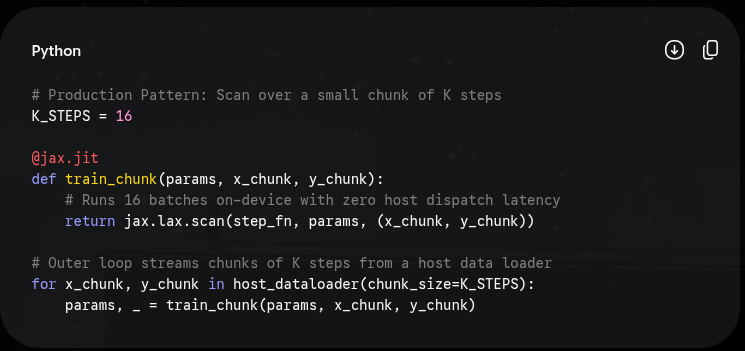